In [1]:
from prophet import Prophet
import pandas as pd
import matplotlib.pyplot as plt
import joblib

# Reload data
df = pd.read_csv('/workspaces/Major_project/data/processed/district_level_data.csv')

# Aggregate yearly
yearly_trend = df.groupby('year').agg({'severity_score': 'sum'}).reset_index()

# Use mid-year dates (June 30th) so years align evenly
prophet_df = pd.DataFrame({
    'ds': pd.to_datetime(yearly_trend['year'].astype(str) + '-06-30'),
    'y': yearly_trend['severity_score']
})

print(prophet_df)

          ds          y
0 2017-06-30  2219987.0
1 2018-06-30  2382332.0
2 2019-06-30  2559149.0
3 2020-06-30  2345987.0
4 2021-06-30  2692687.0
5 2022-06-30  2815576.0
6 2023-06-30  2787535.0


In [2]:
prophet_model = Prophet(
    yearly_seasonality=False,   # Turn off — we only have 7 points
    weekly_seasonality=False,
    daily_seasonality=False,
    interval_width=0.95
)

prophet_model.fit(prophet_df)
print("✅ Prophet retrained with proper dates.")

16:45:38 - cmdstanpy - INFO - Chain [1] start processing
16:45:38 - cmdstanpy - INFO - Chain [1] done processing


✅ Prophet retrained with proper dates.


In [3]:
future = prophet_model.make_future_dataframe(periods=2, freq='YE')
forecast = prophet_model.predict(future)

# Show last 5 rows
print(forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].tail(5))

          ds          yhat    yhat_lower    yhat_upper
4 2021-06-30  2.640766e+06  2.472285e+06  2.825974e+06
5 2022-06-30  2.737438e+06  2.559685e+06  2.923847e+06
6 2023-06-30  2.834110e+06  2.658368e+06  3.023540e+06
7 2023-12-31  2.882843e+06  2.684562e+06  3.078655e+06
8 2024-12-31  2.979780e+06  2.792016e+06  3.168443e+06


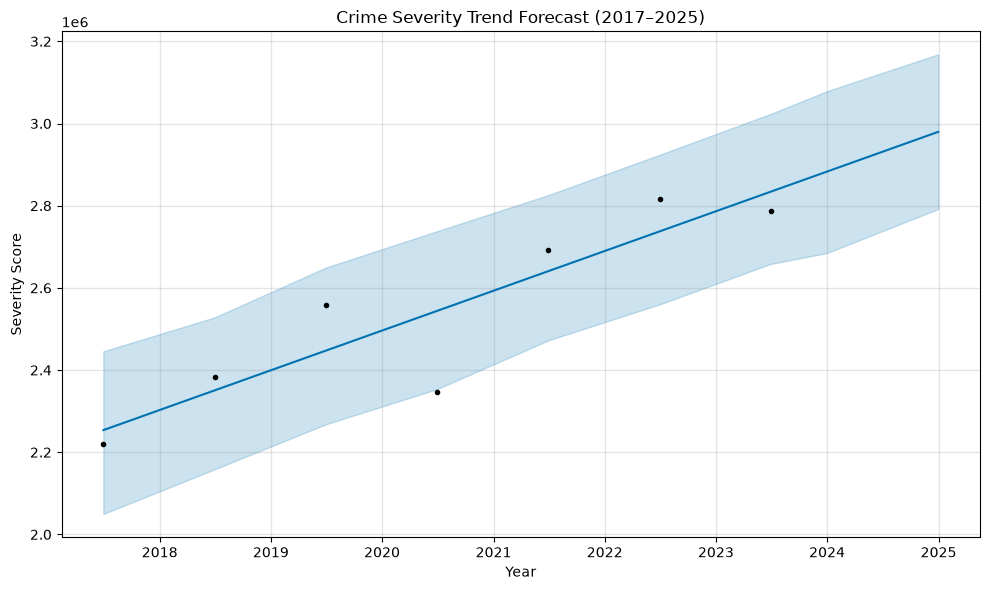

✅ Plot updated


In [4]:
fig, ax = plt.subplots(figsize=(10, 6))
prophet_model.plot(forecast, ax=ax)
ax.set_title("Crime Severity Trend Forecast (2017–2025)")
ax.set_xlabel("Year")
ax.set_ylabel("Severity Score")

plt.tight_layout()
plt.savefig('../reports/prophet_forecast.png', dpi=150)
plt.show()

print("✅ Plot updated")

In [5]:
joblib.dump(prophet_model, '../models/prophet_model.pkl')
print("✅ Prophet model re-saved.")

✅ Prophet model re-saved.


In [6]:
loaded = joblib.load('../models/prophet_model.pkl')
print("✅ Model reloaded successfully.")

✅ Model reloaded successfully.
